In [1]:
import pandas as pd

# Contract-Clause Knowledge Base
knowledge_base = pd.DataFrame({
    "Clause_ID": [
        "C001", "C002", "C003", "C004", "C005",
        "C006", "C007", "C008", "C009", "C010"
    ],

    "Clause_Name": [
        "Delivery Period",
        "Payment Terms",
        "Delay Notification",
        "Penalty / Liquidated Damages",
        "Insurance",
        "Confidentiality",
        "Termination",
        "Force Majeure",
        "Applicable Law",
        "Dispute Resolution"
    ],

    "Requirement": [
        "Vendor must deliver goods within the agreed delivery period.",
        "Payment must be made according to the agreed payment period.",
        "Vendor must notify the company about delivery delays within the specified time.",
        "Vendor may be charged a penalty for delayed delivery.",
        "Vendor must maintain valid insurance coverage.",
        "Vendor must protect confidential business and contract information.",
        "Contract may be terminated according to the agreed termination conditions.",
        "Unavoidable events such as natural disasters may be covered.",
        "Contract must follow the specified applicable laws.",
        "Disputes must be resolved according to the agreed procedure."
    ],

    "Risk_Level": [
        "High",
        "Medium",
        "High",
        "High",
        "High",
        "Medium",
        "High",
        "Medium",
        "Medium",
        "Medium"
    ],

    "Compliance_Check": [
        "Compare planned and actual delivery dates.",
        "Check agreed payment period.",
        "Check whether delay notification was provided on time.",
        "Check whether delay penalty conditions are applicable.",
        "Verify insurance validity.",
        "Verify confidentiality requirements.",
        "Check termination conditions.",
        "Check whether the event qualifies as force majeure.",
        "Verify applicable law requirements.",
        "Verify dispute resolution procedure."
    ]
})

knowledge_base

,Clause_ID,Clause_Name,Requirement,Risk_Level,Compliance_Check
0,C001,Delivery Period,Vendor must deliver goods within the agreed de...,High,Compare planned and actual delivery dates.
1,C002,Payment Terms,Payment must be made according to the agreed p...,Medium,Check agreed payment period.
2,C003,Delay Notification,Vendor must notify the company about delivery ...,High,Check whether delay notification was provided ...
3,C004,Penalty / Liquidated Damages,Vendor may be charged a penalty for delayed de...,High,Check whether delay penalty conditions are app...
4,C005,Insurance,Vendor must maintain valid insurance coverage.,High,Verify insurance validity.
5,C006,Confidentiality,Vendor must protect confidential business and ...,Medium,Verify confidentiality requirements.
6,C007,Termination,Contract may be terminated according to the ag...,High,Check termination conditions.
7,C008,Force Majeure,Unavoidable events such as natural disasters m...,Medium,Check whether the event qualifies as force maj...
8,C009,Applicable Law,Contract must follow the specified applicable ...,Medium,Verify applicable law requirements.
9,C010,Dispute Resolution,Disputes must be resolved according to the agr...,Medium,Verify dispute resolution procedure.


In [2]:
knowledge_base.to_csv(
    "contract_clause_knowledge_base.csv",
    index=False
)

print("Contract-Clause Knowledge Base created successfully!")

Contract-Clause Knowledge Base created successfully!


In [3]:
import os

print(os.path.exists("contract_clause_knowledge_base.csv"))


True


In [4]:
from google.colab import files

files.download("contract_clause_knowledge_base.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
def search_clause(keyword):
    keyword = keyword.lower()

    result = knowledge_base[
        knowledge_base["Clause_Name"].str.lower().str.contains(keyword, na=False)
    ]

    if result.empty:
        print("No matching clause found.")
    else:
        display(result)


# Test the search
search_clause("Delivery")

,Clause_ID,Clause_Name,Requirement,Risk_Level,Compliance_Check
0,C001,Delivery Period,Vendor must deliver goods within the agreed de...,High,Compare planned and actual delivery dates.


In [6]:
search_clause("Insurance")

,Clause_ID,Clause_Name,Requirement,Risk_Level,Compliance_Check
4,C005,Insurance,Vendor must maintain valid insurance coverage.,High,Verify insurance validity.


In [7]:
search_clause("Payment")

,Clause_ID,Clause_Name,Requirement,Risk_Level,Compliance_Check
1,C002,Payment Terms,Payment must be made according to the agreed p...,Medium,Check agreed payment period.


In [8]:
def get_clause_details(clause_name):
    result = knowledge_base[
        knowledge_base["Clause_Name"].str.lower() == clause_name.lower()
    ]

    if result.empty:
        print("Clause not found.")
        return

    row = result.iloc[0]

    print("====================================")
    print("CONTRACT CLAUSE DETAILS")
    print("====================================")
    print("Clause ID:", row["Clause_ID"])
    print("Clause Name:", row["Clause_Name"])
    print("Requirement:", row["Requirement"])
    print("Risk Level:", row["Risk_Level"])
    print("Compliance Check:", row["Compliance_Check"])
    print("====================================")


In [9]:
get_clause_details("Delay Notification")

CONTRACT CLAUSE DETAILS
Clause ID: C003
Clause Name: Delay Notification
Requirement: Vendor must notify the company about delivery delays within the specified time.
Risk Level: High
Compliance Check: Check whether delay notification was provided on time.


In [10]:
get_clause_details("Delay Notification")

CONTRACT CLAUSE DETAILS
Clause ID: C003
Clause Name: Delay Notification
Requirement: Vendor must notify the company about delivery delays within the specified time.
Risk Level: High
Compliance Check: Check whether delay notification was provided on time.


In [13]:
from google.colab import files

uploaded = files.upload()


Saving shipping_data.csv to shipping_data.csv


In [14]:
import os

print("Uploaded files:")
print(os.listdir("/content"))

Uploaded files:
['.config', 'shipping_data.csv', 'contract_clause_knowledge_base.csv', 'sample_data']


In [15]:
import pandas as pd
import os

csv_files = [f for f in os.listdir("/content") if f.lower().endswith(".csv")]

print("CSV files found:", csv_files)

shipping_file = csv_files[0]

shipping_df = pd.read_csv("/content/" + shipping_file)

print("Shipping data loaded successfully!")
print("File:", shipping_file)
print("Shape:", shipping_df.shape)

shipping_df.head()

CSV files found: ['shipping_data.csv', 'contract_clause_knowledge_base.csv']
Shipping data loaded successfully!
File: shipping_data.csv
Shape: (500, 12)


,Shipment_ID,Vendor,Origin,Destination,Shipping_Mode,Distance_km,Weather,Traffic,Planned_Delivery_Days,Actual_Delivery_Days,Delay_Days,Delayed
0,SHP0001,Beta Suppliers,Chennai,Mumbai,Rail,964,Clear,Low,2,2,0,0
1,SHP0002,Omega Supplies,Chennai,Coimbatore,Rail,1002,Rain,Low,3,5,2,1
2,SHP0003,Prime Logistics,Mumbai,Chennai,Rail,1781,Clear,Low,3,3,0,0
3,SHP0004,Beta Suppliers,Coimbatore,Pune,Road,1520,Storm,Medium,3,6,3,1
4,SHP0005,Omega Supplies,Coimbatore,Mumbai,Air,2414,Clear,Low,5,5,0,0


In [16]:
print(shipping_df.columns.tolist())

['Shipment_ID', 'Vendor', 'Origin', 'Destination', 'Shipping_Mode', 'Distance_km', 'Weather', 'Traffic', 'Planned_Delivery_Days', 'Actual_Delivery_Days', 'Delay_Days', 'Delayed']


In [17]:
shipping_df
def get_delay_risk(delay_days):
    if delay_days <= 0:
        return "No Delay"
    elif delay_days <= 2:
        return "Low"
    elif delay_days <= 5:
        return "Medium"
    else:
        return "High"


shipping_df["Delay_Risk"] = shipping_df["Delay_Days"].apply(get_delay_risk)

shipping_df[
    [
        "Shipment_ID",
        "Vendor",
        "Planned_Delivery_Days",
        "Actual_Delivery_Days",
        "Delay_Days",
        "Delay_Risk"
    ]
].head(10)

,Shipment_ID,Vendor,Planned_Delivery_Days,Actual_Delivery_Days,Delay_Days,Delay_Risk
0,SHP0001,Beta Suppliers,2,2,0,No Delay
1,SHP0002,Omega Supplies,3,5,2,Low
2,SHP0003,Prime Logistics,3,3,0,No Delay
3,SHP0004,Beta Suppliers,3,6,3,Medium
4,SHP0005,Omega Supplies,5,5,0,No Delay
5,SHP0006,Epsilon Exports,4,4,0,No Delay
6,SHP0007,Delta Traders,6,7,1,Low
7,SHP0008,Zeta Manufacturing,2,3,1,Low
8,SHP0009,Delta Traders,1,3,2,Low
9,SHP0010,Omega Supplies,2,2,0,No Delay


In [18]:
delay_clauses = knowledge_base[
    knowledge_base["Clause_Name"].isin([
        "Delivery Period",
        "Delay Notification",
        "Penalty / Liquidated Damages"
    ])
]

delay_clauses


,Clause_ID,Clause_Name,Requirement,Risk_Level,Compliance_Check
0,C001,Delivery Period,Vendor must deliver goods within the agreed de...,High,Compare planned and actual delivery dates.
2,C003,Delay Notification,Vendor must notify the company about delivery ...,High,Check whether delay notification was provided ...
3,C004,Penalty / Liquidated Damages,Vendor may be charged a penalty for delayed de...,High,Check whether delay penalty conditions are app...


In [19]:
contract_risk_summary = []

for _, shipment in shipping_df.iterrows():

    if shipment["Delay_Days"] > 0:

        for _, clause in delay_clauses.iterrows():

            contract_risk_summary.append({
                "Shipment_ID": shipment["Shipment_ID"],
                "Vendor": shipment["Vendor"],
                "Delay_Days": shipment["Delay_Days"],
                "Delay_Risk": shipment["Delay_Risk"],
                "Clause_ID": clause["Clause_ID"],
                "Clause_Name": clause["Clause_Name"],
                "Contract_Risk": clause["Risk_Level"],
                "Requirement": clause["Requirement"],
                "Compliance_Check": clause["Compliance_Check"]
            })

contract_risk_df = pd.DataFrame(contract_risk_summary)

contract_risk_df.head(10)

,Shipment_ID,Vendor,Delay_Days,Delay_Risk,Clause_ID,Clause_Name,Contract_Risk,Requirement,Compliance_Check
0,SHP0002,Omega Supplies,2,Low,C001,Delivery Period,High,Vendor must deliver goods within the agreed de...,Compare planned and actual delivery dates.
1,SHP0002,Omega Supplies,2,Low,C003,Delay Notification,High,Vendor must notify the company about delivery ...,Check whether delay notification was provided ...
2,SHP0002,Omega Supplies,2,Low,C004,Penalty / Liquidated Damages,High,Vendor may be charged a penalty for delayed de...,Check whether delay penalty conditions are app...
3,SHP0004,Beta Suppliers,3,Medium,C001,Delivery Period,High,Vendor must deliver goods within the agreed de...,Compare planned and actual delivery dates.
4,SHP0004,Beta Suppliers,3,Medium,C003,Delay Notification,High,Vendor must notify the company about delivery ...,Check whether delay notification was provided ...
5,SHP0004,Beta Suppliers,3,Medium,C004,Penalty / Liquidated Damages,High,Vendor may be charged a penalty for delayed de...,Check whether delay penalty conditions are app...
6,SHP0007,Delta Traders,1,Low,C001,Delivery Period,High,Vendor must deliver goods within the agreed de...,Compare planned and actual delivery dates.
7,SHP0007,Delta Traders,1,Low,C003,Delay Notification,High,Vendor must notify the company about delivery ...,Check whether delay notification was provided ...
8,SHP0007,Delta Traders,1,Low,C004,Penalty / Liquidated Damages,High,Vendor may be charged a penalty for delayed de...,Check whether delay penalty conditions are app...
9,SHP0008,Zeta Manufacturing,1,Low,C001,Delivery Period,High,Vendor must deliver goods within the agreed de...,Compare planned and actual delivery dates.


In [20]:
risk_counts = contract_risk_df["Contract_Risk"].value_counts()

print("Contract Risk Summary:")
print(risk_counts)


Contract Risk Summary:
Contract_Risk
High    1215
Name: count, dtype: int64


In [21]:
contract_risk_df.to_csv(
    "shipment_contract_risk_analysis.csv",
    index=False
)

print("File created successfully!")
print("shipment_contract_risk_analysis.csv")

File created successfully!
shipment_contract_risk_analysis.csv


In [23]:
from google.colab import files

files.download("shipment_contract_risk_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
import matplotlib.pyplot as plt

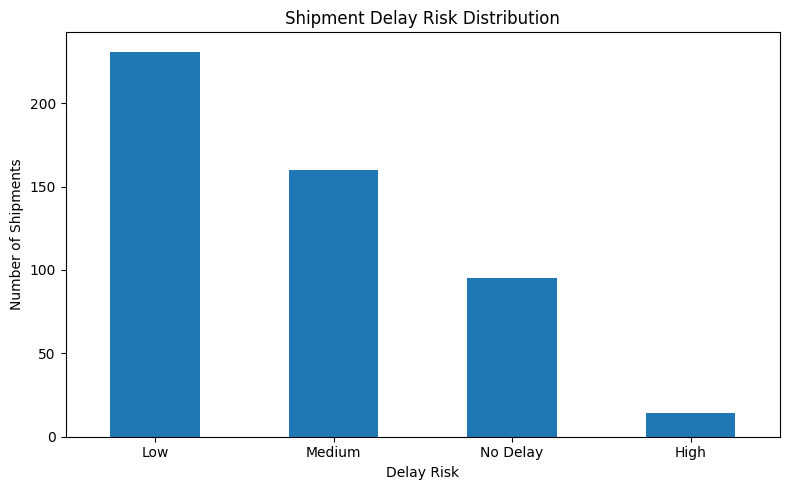

In [26]:
risk_counts = shipping_df["Delay_Risk"].value_counts()

plt.figure(figsize=(8, 5))
risk_counts.plot(kind="bar")

plt.title("Shipment Delay Risk Distribution")
plt.xlabel("Delay Risk")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

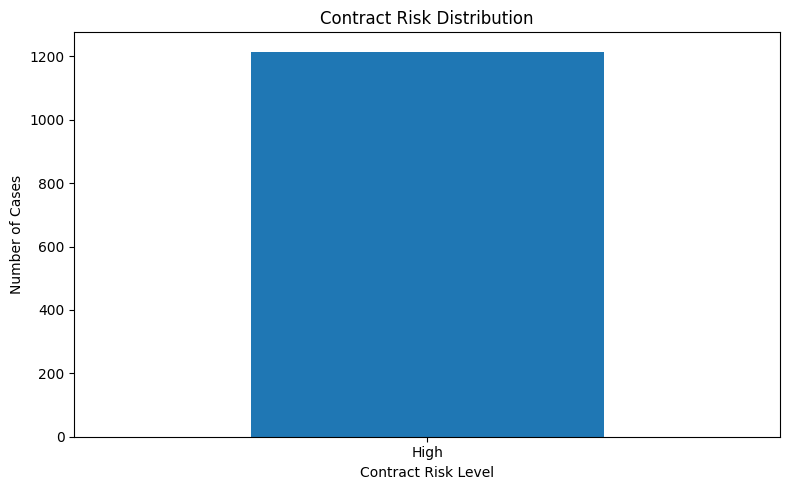

In [27]:
import matplotlib.pyplot as plt

contract_risk_counts = contract_risk_df["Contract_Risk"].value_counts()

plt.figure(figsize=(8, 5))
contract_risk_counts.plot(kind="bar")

plt.title("Contract Risk Distribution")
plt.xlabel("Contract Risk Level")
plt.ylabel("Number of Cases")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

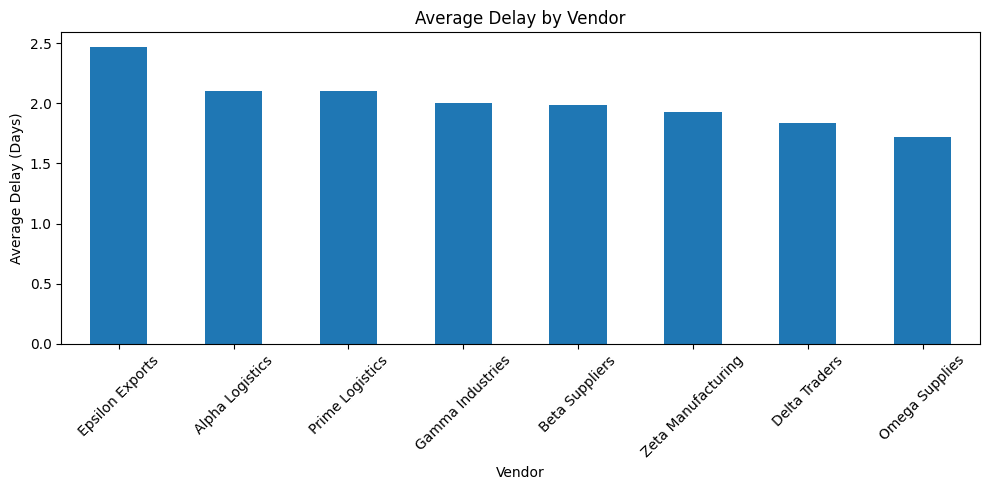

In [28]:
vendor_delay = (
    shipping_df.groupby("Vendor")["Delay_Days"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
vendor_delay.plot(kind="bar")

plt.title("Average Delay by Vendor")
plt.xlabel("Vendor")
plt.ylabel("Average Delay (Days)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

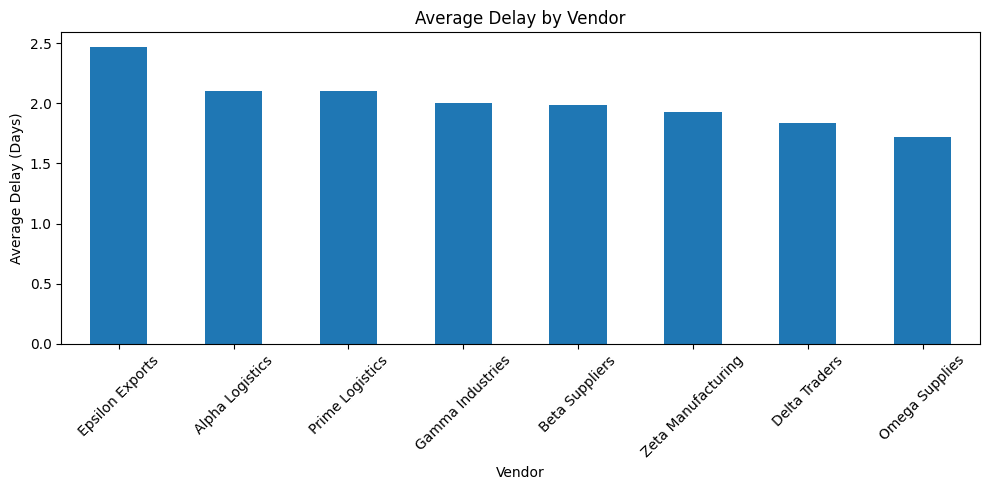

In [29]:
vendor_delay = (
    shipping_df.groupby("Vendor")["Delay_Days"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
vendor_delay.plot(kind="bar")

plt.title("Average Delay by Vendor")
plt.xlabel("Vendor")
plt.ylabel("Average Delay (Days)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [30]:
print("========== DAY 4 SUMMARY ==========")

print("Total Shipments:", len(shipping_df))

print(
    "Delayed Shipments:",
    (shipping_df["Delay_Days"] > 0).sum()
)

print(
    "Total Contract Risk Cases:",
    len(contract_risk_df)
)

print(
    "High Contract Risk Cases:",
    (contract_risk_df["Contract_Risk"] == "High").sum()
)

print("\nContract Clauses Used:")

for clause in delay_clauses["Clause_Name"]:
    print("-", clause)

print("===================================")

========== DAY 4 SUMMARY ==========
Total Shipments: 500
Delayed Shipments: 405
Total Contract Risk Cases: 1215
High Contract Risk Cases: 1215

Contract Clauses Used:
- Delivery Period
- Delay Notification
- Penalty / Liquidated Damages


In [31]:
contract_risk_df.to_csv(
    "shipment_contract_risk_analysis.csv",
    index=False
)

knowledge_base.to_csv(
    "contract_clause_knowledge_base.csv",
    index=False
)

print("Day 4 files saved successfully!")

Day 4 files saved successfully!


In [32]:
from google.colab import files

files.download("contract_clause_knowledge_base.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
files.download("shipment_contract_risk_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>